### Import library(s)

In [2]:
import pandas as pd
import numpy as np

### Import Book-Crossing Dataset

In [4]:
books = pd.read_csv('Books.csv', low_memory=False)
users = pd.read_csv('Users.csv')
ratings = pd.read_csv('Ratings.csv')

### Step 1:
Removing Image-URL-S, Image-URL-M, and Image-URL-L columns from books as image links are not required for tabular ML classification.

In [5]:
books.drop(columns=['Image-URL-S', 'Image-URL-M', 'Image-URL-L'], inplace=True)

### Step 2:
Cleaning the Age column in users by:
- Treating unrealistic ages (< 5 or > 90) as outliers (NaN).
- Filling missing values with the median age.

In [6]:
users.loc[(users['Age'] < 5) | (users['Age'] > 90), 'Age'] = np.nan
users['Age'] = users['Age'].fillna(users['Age'].median())

### Step 3:
Cleaning Year-Of-Publication in books by:
- Converting non-numeric entries to NaN.
- Treating invalid years (< 1900 or > 2026) as outliers (NaN) and filling with the median year.

In [8]:
books['Year-Of-Publication'] = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')
books.loc[(books['Year-Of-Publication'] < 1900) | (books['Year-Of-Publication'] > 2026), 'Year-Of-Publication'] = np.nan
books['Year-Of-Publication'] = books['Year-Of-Publication'].fillna(books['Year-Of-Publication'].median())

### Step 4:
Filling missing values in Book-Author and Publisher with 'Unknown' to retain valid book records.

In [9]:
books['Book-Author'] = books['Book-Author'].fillna('Unknown')
books['Publisher'] = books['Publisher'].fillna('Unknown')

### Step 5:
Removing implicit ratings (Book-Rating == 0) from ratings to keep only explicit user feedback (1–10)

In [10]:
ratings = ratings[ratings['Book-Rating'] > 0]

### Step 6:
Filtering out inactive users (fewer than 10 ratings) and unpopular books (fewer than 10 ratings) to reduce dataset sparsity and noise.

In [11]:
active_users = ratings['User-ID'].value_counts()
ratings = ratings[ratings['User-ID'].isin(active_users[active_users >= 10].index)]

popular_books = ratings['ISBN'].value_counts()
ratings = ratings[ratings['ISBN'].isin(popular_books[popular_books >= 10].index)]

### Step 7:
Merging ratings, books, and users into a single DataFrame df on ISBN and User-ID.

In [12]:
df = ratings.merge(books, on='ISBN').merge(users, on='User-ID')

### Step 8:
Removing completely duplicated rows and resetting the DataFrame index.

In [13]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

### Step 9:
Checking missing values in each column and final dataset dimensions after preprocessing.

In [14]:
df.isna().sum()

User-ID                0
ISBN                   0
Book-Rating            0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
Location               0
Age                    0
dtype: int64

In [15]:
df.shape

(73490, 9)

### Step 10:
Creating the binary target column Liked (1 if Book-Rating >= 8, else 0) to frame recommendation as a classification problem, and checking class balance.

In [16]:
df['Liked'] = (df['Book-Rating'] >= 8).astype(int)
df['Liked'].value_counts(normalize=True)

Liked
1    0.642183
0    0.357817
Name: proportion, dtype: float64

### Step 11:
Extracting Country from Location (formatted as city, state, country) and grouping less frequent countries into 'other' to reduce high cardinality.

In [17]:
df['Country'] = df['Location'].str.split(',').str[-1].str.strip().str.lower()

top_countries = df['Country'].value_counts().head(10).index
df['Country'] = df['Country'].where(df['Country'].isin(top_countries), 'other')

### Step 12:
Creating User_Activity (total ratings per user) and Book_Popularity (total ratings per book) as numerical interaction features.

In [18]:
df['User_Activity'] = df.groupby('User-ID')['Book-Rating'].transform('count')
df['Book_Popularity'] = df.groupby('ISBN')['Book-Rating'].transform('count')

### Step 13:
Applying frequency encoding to Book-Author and Publisher to convert high-cardinality text columns into numerical features without exploding dimensionality.

In [19]:
df['Author_Freq'] = df['Book-Author'].map(df['Book-Author'].value_counts())
df['Publisher_Freq'] = df['Publisher'].map(df['Publisher'].value_counts())

### Step 14:
One-hot encoding Country and preparing the final feature matrix X and target vector y.

In [20]:
df_encoded = pd.get_dummies(df, columns=['Country'], drop_first=True)

feature_cols = [
    'Age', 'Year-Of-Publication', 'User_Activity',
    'Book_Popularity', 'Author_Freq', 'Publisher_Freq'
] + [col for col in df_encoded.columns if col.startswith('Country_')]

X = df_encoded[feature_cols]
y = df_encoded['Liked']

X.shape

(73490, 16)

### Step 15:
#### (a)
Splitting the dataset into 80% training and 20% testing sets using stratified sampling (stratify=y) to preserve the Liked class ratio in both splits.

In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pd.DataFrame({
    'Split': ['X_train', 'X_test', 'y_train', 'y_test'],
    'Rows': [X_train.shape[0], X_test.shape[0], y_train.shape[0], y_test.shape[0]]
})

,Split,Rows
0,X_train,58792
1,X_test,14698
2,y_train,58792
3,y_test,14698


#### (b)
Adding `User_Avg_Rating` and `Book_Avg_Rating` using only `X_train` so the model does not peek at test data (preventing data leakage). Any unseen user or book in `X_test` is filled with the overall training average.

In [30]:
X_train = X_train.copy()
X_test = X_test.copy()

train_df = df.loc[X_train.index]
global_mean = train_df['Book-Rating'].mean()

user_avg_map = train_df.groupby('User-ID')['Book-Rating'].mean()
book_avg_map = train_df.groupby('ISBN')['Book-Rating'].mean()

X_train['User_Avg_Rating'] = df.loc[X_train.index, 'User-ID'].map(user_avg_map).fillna(global_mean)
X_train['Book_Avg_Rating'] = df.loc[X_train.index, 'ISBN'].map(book_avg_map).fillna(global_mean)

X_test['User_Avg_Rating'] = df.loc[X_test.index, 'User-ID'].map(user_avg_map).fillna(global_mean)
X_test['Book_Avg_Rating'] = df.loc[X_test.index, 'ISBN'].map(book_avg_map).fillna(global_mean)

feature_cols = list(X_train.columns)
X_train.shape

(58792, 18)

### Step 16:
Scaling features using StandardScaler (required for SVM, which is sensitive to feature magnitudes). Fitting only on X_train to prevent data leakage.

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 17:
Importing the three classification algorithms (Decision Tree, SVM, Random Forest) and evaluation metrics.



In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

### Step 18:
Training the Decision Tree Classifier (with max_depth=10 to prevent overfitting) and predicting on X_test.

In [33]:
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

### Step 19:
Training the Support Vector Machine (LinearSVC) on the scaled features (X_train_scaled, X_test_scaled).

In [34]:
svm_model = LinearSVC(random_state=42, max_iter=2000)
svm_model.fit(X_train_scaled, y_train)
svm_pred = svm_model.predict(X_test_scaled)

### Step 20:
Training the Random Forest Classifier (ensemble of 100 trees) and predicting on X_test.

In [35]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

### Step 21:
Comparing Accuracy, Precision, Recall, and F1-Score across all three models in a single DataFrame.


In [36]:
results = []

for name, preds in [
    ('Decision Tree', dt_pred),
    ('SVM (LinearSVC)', svm_pred),
    ('Random Forest', rf_pred)
]:
    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4),
        'F1-Score': round(f1_score(y_test, preds), 4)
    })

comparison_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False).reset_index(drop=True)
comparison_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.7072,0.7374,0.8450,0.7875
1,SVM (LinearSVC),0.7059,0.7355,0.8463,0.7870
2,Decision Tree,0.6984,0.7344,0.8308,0.7796


### Step 22:
Plotting side-by-side Confusion Matrices for all three models to visually compare their correct and incorrect predictions.

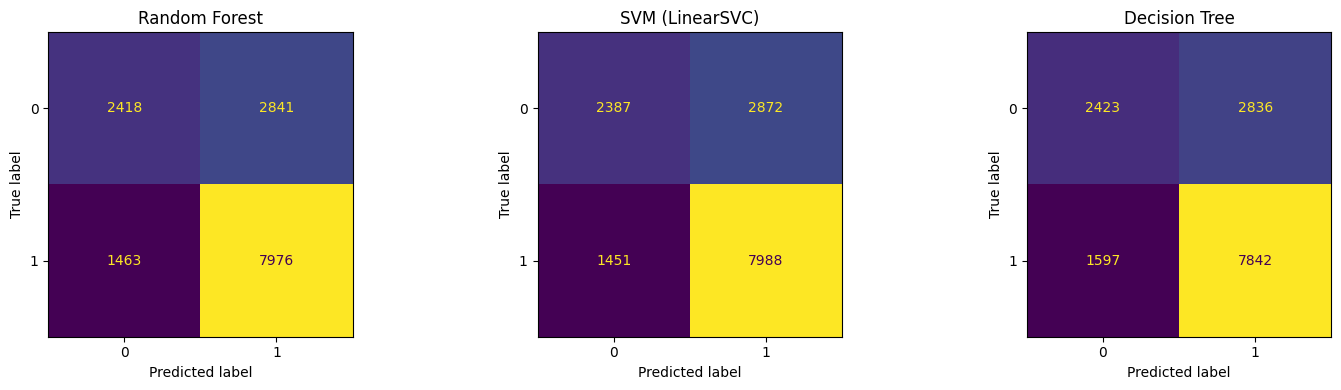

In [37]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models_preds = [
    ('Random Forest', rf_pred),
    ('SVM (LinearSVC)', svm_pred),
    ('Decision Tree', dt_pred)
]

for ax, (name, preds) in zip(axes, models_preds):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Step 23:
Saving all three trained models (Random Forest, Decision Tree, SVM), the StandardScaler, feature list, benchmark table, and deduplicated book catalog for the Streamlit UI.

In [38]:
import joblib

joblib.dump(rf_model, 'rf_book_model.pkl')
joblib.dump(dt_model, 'dt_book_model.pkl')
joblib.dump(svm_model, 'svm_book_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

joblib.dump(feature_cols, 'feature_cols.pkl')
comparison_df.to_csv('model_comparison.csv', index=False)

book_catalog = df[[
    'ISBN', 'Book-Title', 'Book-Author', 'Publisher',
    'Year-Of-Publication', 'Book_Popularity', 'Author_Freq', 'Publisher_Freq'
]].drop_duplicates(subset='ISBN').reset_index(drop=True)

book_catalog['Book_Avg_Rating'] = book_catalog['ISBN'].map(book_avg_map).fillna(global_mean)
book_catalog.to_csv('book_catalog.csv', index=False)

book_catalog.shape

(3331, 9)